# 03 - Model Evaluation

Three different things are reported here - keep them separate:

1. **Training-time metrics** (from notebook 02): measured on the *validation* set after each epoch.
   The best epoch is picked using this set, so it is slightly optimistic.
2. **Final validation metrics**: re-run on `val` with `models/best.pt`.
3. **Test metrics**: the `test` split, never used for training or for choosing the model - the
   fairest estimate of unseen-data performance.
Then qualitative inference examples on test images. Every number below comes from actually running the model.

In [1]:
import sys
from pathlib import Path

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "scripts").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
from common import *
print("Project root:", ROOT)

Project root: C:\Users\GIGABYTE\Downloads\YOLO_Object_Detection\YOLO_Object_Detection


In [2]:
import json, shutil
import cv2, pandas as pd, matplotlib.pyplot as plt
from ultralytics import YOLO

if not BEST_MODEL.exists():
    raise FileNotFoundError(f"{BEST_MODEL} missing - run notebook 02 first")
DATA_YAML = DATASET_DIR / "dataset.yaml"
model = YOLO(str(BEST_MODEL))
print("Classes:", model.names)

Classes: {0: 'car', 1: 'van', 2: 'truck', 3: 'pedestrian', 4: 'Person_sitting', 5: 'cyclist', 6: 'tram', 7: 'misc'}


## Validation and test metrics

In [3]:
EVAL_DIR = OUTPUTS_DIR / "metrics"
EVAL_DIR.mkdir(parents=True, exist_ok=True)
summary, per_class = {}, {}
for split in ("val", "test"):
    m = model.val(data=str(DATA_YAML), split=split, plots=True, verbose=False,
                  project=str(OUTPUTS_DIR / "eval_runs"), name=split, exist_ok=True)
    summary[split] = {
        "precision": float(m.box.mp), "recall": float(m.box.mr),
        "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map),
    }
    per_class[split] = pd.DataFrame({
        "class": [model.names[i] for i in m.box.ap_class_index],
        "precision": m.box.p, "recall": m.box.r,
        "mAP50": m.box.ap50, "mAP50-95": m.box.ap,
    })
    # keep the auto-generated confusion matrix and PR/F1 curves
    for f in Path(m.save_dir).glob("*.png"):
        if any(k in f.name for k in ("confusion", "PR_curve", "F1_curve", "P_curve", "R_curve")):
            shutil.copy2(f, EVAL_DIR / f"{split}_{f.name}")

table = pd.DataFrame(summary).T
display(table.round(4))
for split, d in per_class.items():
    print(f"\nPer-class ({split}):"); display(d.round(4))
(EVAL_DIR / "metrics.json").write_text(json.dumps(summary, indent=2))

Ultralytics 8.4.164  Python-3.13.2 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)


YOLO11n summary (fused): 100 layers, 2,583,712 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 523.0166.4 MB/s, size: 47.0 KB)


val: Scanning C:\Users\GIGABYTE\Downloads\YOLO_Object_Detection\YOLO_Object_Detection\data\dataset\labels\val.cache... 1496 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1496/1496 285.2Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 1/94 56.3s/it 16.9s<1:27:14

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 2/94 1.0s/it 17.2s<1:35

... (168 outputs left out)

,class,precision,recall,mAP50,mAP50-95
0,car,0.7306,0.8758,0.8957,0.6333
1,van,0.5858,0.6364,0.6493,0.4315
2,truck,0.5916,0.8447,0.8274,0.5832
3,pedestrian,0.6822,0.4728,0.5363,0.2346
4,Person_sitting,0.8810,0.1652,0.4262,0.1934
5,cyclist,0.6043,0.3028,0.3992,0.1975
6,tram,0.6300,0.8351,0.7446,0.4218
7,misc,0.7594,0.3681,0.4443,0.2987



Per-class (test):


,class,precision,recall,mAP50,mAP50-95
0,car,0.7557,0.8722,0.8932,0.6287
1,van,0.5532,0.6598,0.6684,0.4646
2,truck,0.6332,0.7500,0.7369,0.4978
3,pedestrian,0.6777,0.4250,0.5150,0.2151
4,Person_sitting,0.7197,0.2105,0.3141,0.1500
5,cyclist,0.6660,0.3136,0.4569,0.2314
6,tram,0.7361,0.8537,0.8661,0.5042
7,misc,0.6215,0.2632,0.3624,0.2449


314

## Confusion matrix and precision-recall curve (test split)

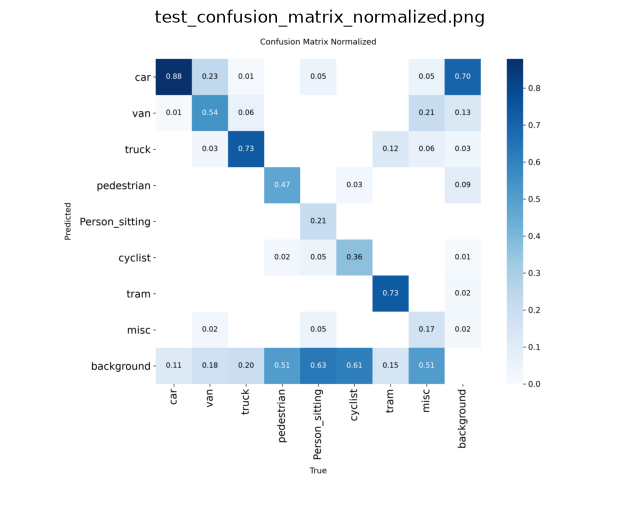

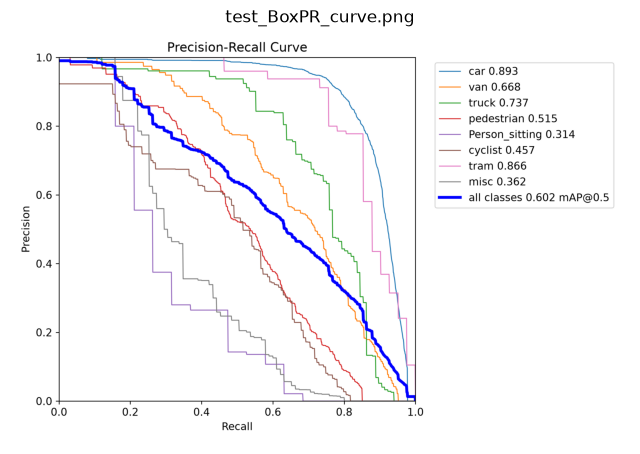

In [4]:
for name in ("test_confusion_matrix_normalized.png", "test_BoxPR_curve.png"):
    p = EVAL_DIR / name
    if p.exists():
        plt.figure(figsize=(8, 7)); plt.imshow(plt.imread(p)); plt.axis("off"); plt.title(name); plt.show()
    else:
        print("Not produced:", name, "(file names differ by Ultralytics version; see", EVAL_DIR, ")")

## Inference on unseen test images

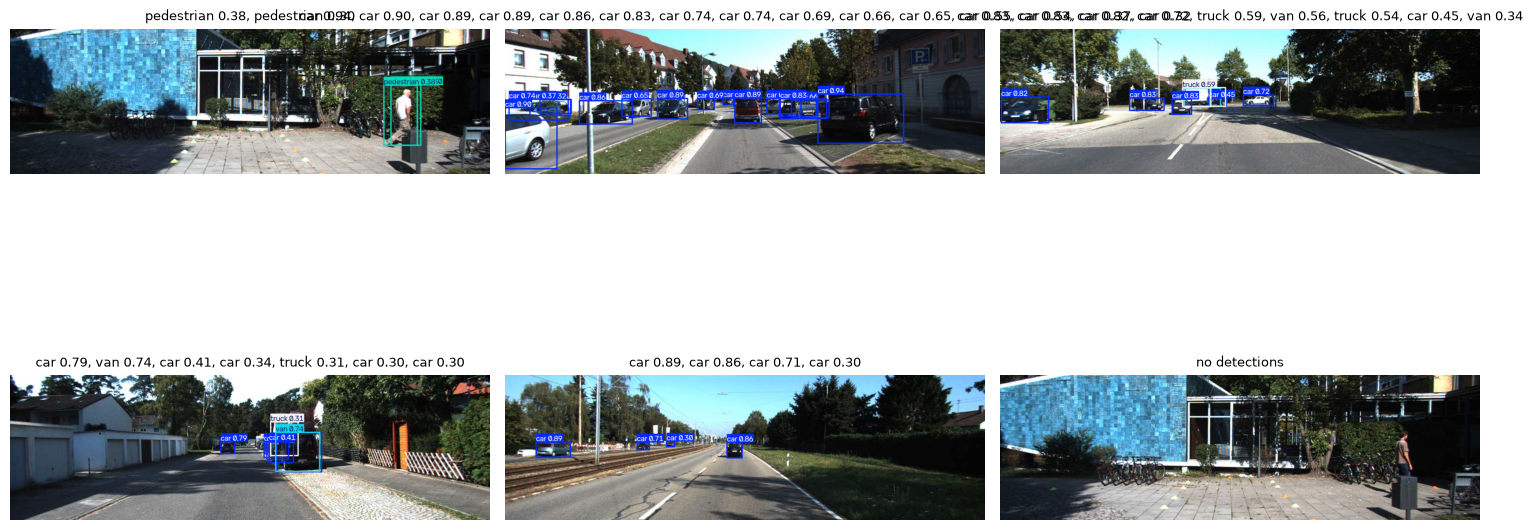

Saved predictions to C:\Users\GIGABYTE\Downloads\YOLO_Object_Detection\YOLO_Object_Detection\outputs\predictions


In [5]:
import random
test_imgs = sorted((DATASET_DIR / "images" / "test").iterdir())
random.Random(SEED).shuffle(test_imgs)
pred_dir = OUTPUTS_DIR / "predictions"
pred_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axes.ravel(), test_imgs[:6]):
    r = model.predict(str(p), conf=0.25, verbose=False)[0]
    annotated = r.plot()                       # BGR with boxes, class names, confidences
    cv2.imwrite(str(pred_dir / f"pred_{p.stem}.jpg"), annotated)
    ax.imshow(annotated[:, :, ::-1]); ax.axis("off")
    ax.set_title(", ".join(f"{model.names[int(b.cls)]} {float(b.conf):.2f}" for b in r.boxes) or "no detections", fontsize=9)
plt.tight_layout(); plt.show()
print("Saved predictions to", pred_dir)

Next steps: run `python scripts/run_tests.py` for the 5 qualitative tests, then
`streamlit run app/app.py`. Copy the numbers printed above into the README "Performance metrics" section.